# RSS reconstruction across GuFu stages

This notebook measures **how well each saved AE checkpoint reconstructs actual RSS scans**, in dB, for both the bootstrap reference scans and the incoming update scans. It follows the paper's RSS-error idea: compare reconstructed RSS against actually measured RSS, and ignore AP cells that were not observed. The primary score is cell-weighted mean absolute error (MAE); RMSE and signed bias are shown as supporting diagnostics. The paper describes the RSS error as the average difference between updated and measured RSS, but does not spell out the absolute-value/aggregation details, so MAE is the explicit non-cancelling interpretation used here. [GuFu paper, evaluation metrics](https://www.cse.ust.hk/~gchan/papers/IMWUT25_GUFU.pdf) 

The AE output is converted from the saved normalization back to dBm before scoring. Missing RSS values are excluded by the measurement mask, never by guessing from a sentinel value.

**What the stages mean:**

1. Bootstrap AE, trained on reference scans only.
2. Round 1 Eq. (10) AE update, trained on labeled reference scans.
3. AP-vocabulary-migrated AE, before post-transition fine-tuning.
4. Post-transition AE, fine-tuned with reference anchors and measured update RSS.
5. Round 2 Eq. (10) AE update, whose parent checkpoint has already seen update RSS.

The update scans are held out from the bootstrap AE and the round 1 AE *checkpoint*. Post-transition AE training uses their measured RSS, so its update score is in-sample; round 2 inherits that exposure. The saved bootstrap AE used all reference scans, so its reference score is in-sample. This notebook does not call a subset of those training scans “held out.”

We score the same raw scans at each stage, projecting them into each checkpoint's BSSID vocabulary. The `all-stage-common APs` rows keep the AP set fixed for a clean stage-to-stage comparison; `stage vocabulary` rows include every measured AP that checkpoint can represent. Both report coverage so a lower score cannot hide a smaller scored AP set.

This is **direct AE reconstruction** (`x → E(x) → D(E(x))`). The final section separately scores the GNN/updater-to-decoder path on update scans, using the existing chain diagnostic. These are different questions: the direct AE table isolates the AE, while the chain table includes the GNN and localization/update heads.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

from ae import load_ae_checkpoint
from gufu_data import ae_input_observation_mask, load_prepared_dataset
from gufu_debug_evaluation import _latest_snapshot, evaluate_debug_run

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "gufu.py").is_file():
    raise RuntimeError("Run this notebook with the GUFU repository root as the working directory.")

OUTPUT_ROOTS = {
    "GF_from1F_12": PROJECT_ROOT / "output_from1F_12",
    "GF_fromGF_12": PROJECT_ROOT / "output_fromGF_12",
}
DEVICE = "cpu"
BATCH_SIZE = 256


## 1. Load the saved AE checkpoints and the two scan sets

The notebook uses only the completed artifacts in each output directory. Reference scans come from the original bootstrap dataset; update scans come from the batch saved in the completed snapshot. Checkpoint stage and exposure are recorded with each result.


In [2]:
STAGE_DEFINITIONS = (
    (
        "bootstrap_AE",
        lambda run_root, snapshot: run_root / "checkpoints" / "ae.pt",
        "Reference scans only",
    ),
    (
        "round1_Eq10_AE",
        lambda run_root, snapshot: snapshot / "ae_update" / "updated_ae.pt",
        "Reference scans only; update RSS not used in this AE loss",
    ),
    (
        "post_AP_migration_AE",
        lambda run_root, snapshot: snapshot / "migrated_ae.pt",
        "Vocabulary migration only; no post-transition fine-tuning yet",
    ),
    (
        "post_transition_AE",
        lambda run_root, snapshot: snapshot / "post_transition_ae" / "post_transition_ae.pt",
        "Reference anchors plus measured update RSS",
    ),
    (
        "round2_Eq10_AE",
        lambda run_root, snapshot: snapshot / "post_transition_fingerprint_update_round2" / "ae_update" / "updated_ae.pt",
        "Reference Eq. (10) update; parent AE was trained on update RSS",
    ),
)

run_artifacts = {}
for run_name, output_root in OUTPUT_ROOTS.items():
    if not output_root.is_dir():
        raise FileNotFoundError(f"Saved output directory not found: {output_root}")
    snapshot_dir, snapshot_manifest, run_root = _latest_snapshot(output_root)
    reference = load_prepared_dataset(run_root / "prepared_bootstrap.json")
    update = load_prepared_dataset(snapshot_dir / "input_prepared_batch.json")
    stages = []
    for stage_name, path_builder, exposure in STAGE_DEFINITIONS:
        checkpoint_path = path_builder(run_root, snapshot_dir)
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f"Missing {stage_name} checkpoint: {checkpoint_path}")
        checkpoint = load_ae_checkpoint(checkpoint_path, device=DEVICE, dtype="float32")
        stages.append({
            "name": stage_name,
            "path": checkpoint_path,
            "exposure": exposure,
            "checkpoint": checkpoint,
            "vocabulary": tuple(checkpoint.manifest.bssid_vocabulary),
            "normalization": checkpoint.manifest.normalization,
        })
    common_vocabulary = set(stages[0]["vocabulary"])
    for stage in stages[1:]:
        common_vocabulary.intersection_update(stage["vocabulary"])
    run_artifacts[run_name] = {
        "snapshot_dir": snapshot_dir,
        "snapshot_manifest": snapshot_manifest,
        "run_root": run_root,
        "reference": reference,
        "update": update,
        "stages": stages,
        "common_vocabulary": common_vocabulary,
    }
    print(
        f"{run_name}: {len(reference.scans):,} reference scans, "
        f"{len(update.scans):,} update scans, "
        f"{len(common_vocabulary):,} APs shared by all five AE checkpoints"
    )


GF_from1F_12: 258 reference scans, 419 update scans, 317 APs shared by all five AE checkpoints
GF_fromGF_12: 2,078 reference scans, 1,733 update scans, 1,022 APs shared by all five AE checkpoints


## 2. Compute direct AE reconstruction errors

For each scan, the model receives the RSS vector in its own BSSID order and the run's recorded AE normalization. We then invert the normalization and score only AP readings that were physically measured in that scan. `MAE_dB` is pooled across all measured cells, matching the paper's average-error framing; `mean_scan_MAE_dB` gives every scan equal weight. The common-AP view excludes access points absent from any one checkpoint, while the stage-vocabulary view uses all measured APs represented at that stage.


In [3]:
def _aligned_scan_arrays(dataset, target_vocabulary, normalization):
    scans = dataset.scans
    source_columns = {bssid: col for col, bssid in enumerate(dataset.bssid_vocabulary)}
    target_vocabulary = tuple(target_vocabulary)
    n_scans, n_aps = len(scans), len(target_vocabulary)

    raw_dbm = np.full((n_scans, n_aps), -120.0, dtype=np.float32)
    input_mask = np.zeros((n_scans, n_aps), dtype=bool)
    score_mask = np.zeros((n_scans, n_aps), dtype=bool)
    for target_col, bssid in enumerate(target_vocabulary):
        source_col = source_columns.get(bssid)
        if source_col is None:
            continue
        raw_dbm[:, target_col] = np.asarray(
            [scan.rss_dbm[source_col] for scan in scans], dtype=np.float32
        )
        input_mask[:, target_col] = np.asarray(
            [ae_input_observation_mask(scan)[source_col] for scan in scans], dtype=bool
        )
        score_mask[:, target_col] = np.asarray(
            [
                scan.observation_mask[source_col]
                and (
                    scan.value_provenance is None
                    or scan.value_provenance[source_col] == "measured"
                )
                for scan in scans
            ],
            dtype=bool,
        )

    if normalization == "paper_ae":
        inputs = np.where(input_mask, (raw_dbm + 120.0) / 120.0, 0.0)
    elif normalization == "legacy_raw_div_120":
        inputs = np.where(input_mask, raw_dbm / 120.0, -1.0)
    else:
        raise ValueError(f"Unsupported AE normalization: {normalization}")
    return inputs.astype(np.float32), raw_dbm, score_mask


def _reconstruct_dbm(stage, inputs):
    model = stage["checkpoint"].model.eval()
    rows = []
    with torch.inference_mode():
        for start in range(0, len(inputs), BATCH_SIZE):
            batch = torch.as_tensor(
                inputs[start : start + BATCH_SIZE], dtype=torch.float32, device=DEVICE
            ).unsqueeze(1)
            _latent, reconstructed = model(batch)
            rows.append(reconstructed[:, 0, :].cpu().numpy())
    normalized = np.concatenate(rows, axis=0)
    if stage["normalization"] == "paper_ae":
        return normalized * 120.0 - 120.0
    return normalized * 120.0


def _error_summary(run_name, stage, cohort, scope, dataset, vocabulary, prediction, target, measured_mask):
    if scope == "all-stage-common APs":
        measured_mask = measured_mask & np.isin(vocabulary, list(run_artifacts[run_name]["common_vocabulary"]))[None, :]
    total_measured = sum(sum(scan.observation_mask) for scan in dataset.scans)
    cell_count = int(measured_mask.sum())
    if cell_count == 0:
        raise ValueError(f"{run_name}/{stage['name']}/{cohort}: no measured cells to score")
    error = prediction - target
    absolute = np.abs(error[measured_mask])
    squared = np.square(error[measured_mask])
    per_scan_mae = []
    for row in range(len(dataset.scans)):
        row_mask = measured_mask[row]
        if row_mask.any():
            per_scan_mae.append(float(np.mean(np.abs(error[row, row_mask]))))
    return {
        "run": run_name,
        "stage": stage["name"],
        "scan_set": cohort,
        "AP_scope": scope,
        "AE_APs": len(vocabulary),
        "scans": len(dataset.scans),
        "scans_scored": len(per_scan_mae),
        "measured_cells_scored": cell_count,
        "measured_cell_coverage_pct": 100.0 * cell_count / max(total_measured, 1),
        "RSS_MAE_dB": float(np.mean(absolute)),
        "RSS_RMSE_dB": float(np.sqrt(np.mean(squared))),
        "RSS_signed_bias_dB": float(np.mean(error[measured_mask])),
        "mean_scan_MAE_dB": float(np.mean(per_scan_mae)),
        "P90_scan_MAE_dB": float(np.quantile(per_scan_mae, 0.90)),
        "AE_update_RSS_exposure": stage["exposure"],
    }


reconstruction_rows = []
for run_name, run in run_artifacts.items():
    for stage in run["stages"]:
        for cohort, dataset in (("reference", run["reference"]), ("update", run["update"])):
            inputs, target_dbm, measured_mask = _aligned_scan_arrays(
                dataset, stage["vocabulary"], stage["normalization"]
            )
            prediction_dbm = _reconstruct_dbm(stage, inputs)
            for scope in ("all-stage-common APs", "stage vocabulary"):
                reconstruction_rows.append(
                    _error_summary(
                        run_name,
                        stage,
                        cohort,
                        scope,
                        dataset,
                        stage["vocabulary"],
                        prediction_dbm,
                        target_dbm,
                        measured_mask,
                    )
                )

reconstruction = pd.DataFrame(reconstruction_rows)
stage_order = [stage[0] for stage in STAGE_DEFINITIONS]
reconstruction["_stage_order"] = reconstruction["stage"].map(
    {name: index for index, name in enumerate(stage_order)}
)
display(
    reconstruction.sort_values(["run", "scan_set", "AP_scope", "_stage_order"])
    .drop(columns="_stage_order")
    .reset_index(drop=True)
)


,run,stage,scan_set,AP_scope,AE_APs,scans,scans_scored,measured_cells_scored,measured_cell_coverage_pct,RSS_MAE_dB,RSS_RMSE_dB,RSS_signed_bias_dB,mean_scan_MAE_dB,P90_scan_MAE_dB,AE_update_RSS_exposure
0,GF_from1F_12,bootstrap_AE,reference,all-stage-common APs,317,258,258,12786,100.000000,8.287745,12.255468,-7.626393,8.125256,10.881291,Reference scans only
1,GF_from1F_12,round1_Eq10_AE,reference,all-stage-common APs,317,258,258,12786,100.000000,9.430049,13.375624,-8.367245,9.308376,12.546705,Reference scans only; update RSS not used in t...
2,GF_from1F_12,post_AP_migration_AE,reference,all-stage-common APs,319,258,258,12786,100.000000,9.430049,13.375624,-8.367245,9.308376,12.546705,Vocabulary migration only; no post-transition ...
3,GF_from1F_12,post_transition_AE,reference,all-stage-common APs,319,258,258,12786,100.000000,8.183263,12.000070,-7.421020,8.234767,11.973377,Reference anchors plus measured update RSS
4,GF_from1F_12,round2_Eq10_AE,reference,all-stage-common APs,319,258,258,12786,100.000000,7.150108,10.425810,-6.522895,7.106686,10.390915,Reference Eq. (10) update; parent AE was train...
5,GF_from1F_12,bootstrap_AE,reference,stage vocabulary,317,258,258,12786,100.000000,8.287745,12.255468,-7.626393,8.125256,10.881291,Reference scans only
6,GF_from1F_12,round1_Eq10_AE,reference,stage vocabulary,317,258,258,12786,100.000000,9.430049,13.375624,-8.367245,9.308376,12.546705,Reference scans only; update RSS not used in t...
7,GF_from1F_12,post_AP_migration_AE,reference,stage vocabulary,319,258,258,12786,100.000000,9.430049,13.375624,-8.367245,9.308376,12.546705,Vocabulary migration only; no post-transition ...
8,GF_from1F_12,post_transition_AE,reference,stage vocabulary,319,258,258,12786,100.000000,8.183263,12.000070,-7.421020,8.234767,11.973377,Reference anchors plus measured update RSS
9,GF_from1F_12,round2_Eq10_AE,reference,stage vocabulary,319,258,258,12786,100.000000,7.150108,10.425810,-6.522895,7.106686,10.390915,Reference Eq. (10) update; parent AE was train...


## 3. Compare the same AP set across stages

This plot uses only APs available to every saved AE checkpoint. Reference reconstruction is in-sample for the bootstrap models. Update reconstruction is the temporal holdout for the bootstrap and round 1 AE checkpoints; post-transition and round 2 have the update-RSS exposure described above.


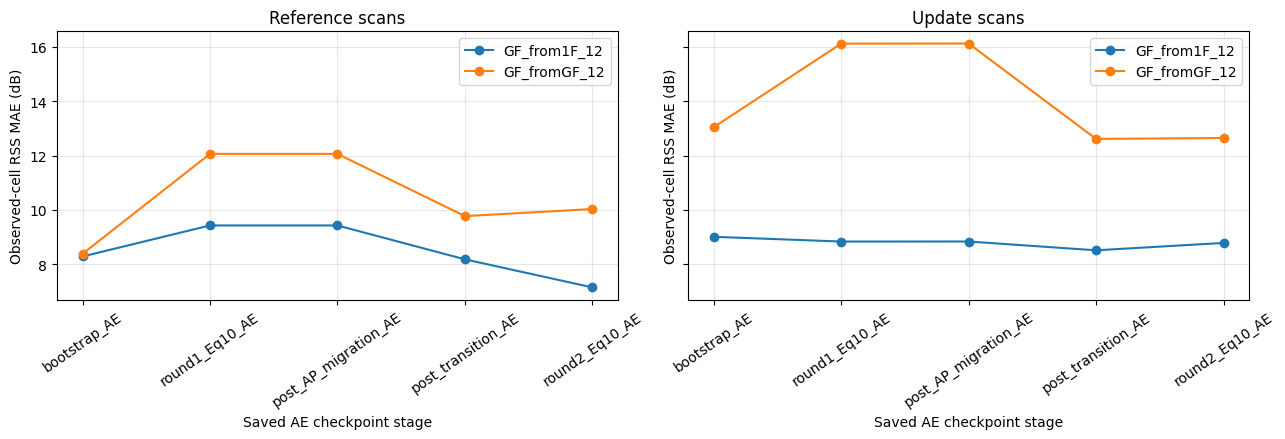

In [4]:
plot_data = reconstruction[reconstruction["AP_scope"] == "all-stage-common APs"].copy()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, cohort in zip(axes, ("reference", "update")):
    subset = plot_data[plot_data["scan_set"] == cohort]
    for run_name, frame in subset.groupby("run", sort=False):
        frame = frame.sort_values("_stage_order")
        ax.plot(frame["stage"], frame["RSS_MAE_dB"], marker="o", label=run_name)
    ax.set_title(f"{cohort.capitalize()} scans")
    ax.set_ylabel("Observed-cell RSS MAE (dB)")
    ax.set_xlabel("Saved AE checkpoint stage")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()


## 4. Check the complete GNN-to-RSS path on update scans

The table below uses the saved online round 1 and post-transition round 2 graphs, GNNs, and updater heads. For each incoming scan it compares three decoder inputs against that scan's measured RSS:

- `predicted_position`: the actual inference chain, `GNN embedding → location MLP → position-to-feature MLP → AE decoder`.
- `true_position`: an oracle diagnostic that substitutes the scan's known coordinate into the position-to-feature MLP. Its coordinate is used only for evaluation.
- `AE_target`: direct `AE encoder → AE decoder` reconstruction of the incoming scan, without the GNN/updater chain.

This is the closest saved-artifact check of whether error enters through the GNN/location path or through the AE representation/decoder. It is still a scan reconstruction metric; the paper's RSS error is applied to updated fingerprints and fresh measurements.


In [5]:
chain_summaries = []
for run_name, output_root in OUTPUT_ROOTS.items():
    summary, _per_scan = evaluate_debug_run(
        run_name, output_root, device_override=DEVICE
    )
    wanted = [
        "run",
        "updater_round",
        "held_out_scans",
        "mean_measured_AP_coverage_percent",
        "decoded_RSS_predicted_position_MAE_dBm",
        "decoded_RSS_true_position_MAE_dBm",
        "decoded_RSS_AE_target_MAE_dBm",
    ]
    chain_summaries.append(summary[wanted])

chain_reconstruction = pd.concat(chain_summaries, ignore_index=True)
display(chain_reconstruction)


,run,updater_round,held_out_scans,mean_measured_AP_coverage_percent,decoded_RSS_predicted_position_MAE_dBm,decoded_RSS_true_position_MAE_dBm,decoded_RSS_AE_target_MAE_dBm
0,GF_from1F_12,online_updater_round1_fingerprints,419,12.867628,7.871135,7.048191,8.115312
1,GF_from1F_12,post_transition_updater_round2_fingerprints,419,12.867628,6.690910,5.541044,5.066657
2,GF_fromGF_12,online_updater_round1_fingerprints,1733,3.729935,21.297280,18.823200,14.556502
3,GF_fromGF_12,post_transition_updater_round2_fingerprints,1733,3.729935,18.274922,16.507438,12.981149


## Reading the results

- Start with `all-stage-common APs` to see whether reconstruction improves on an unchanged AP set. Then inspect `stage vocabulary` to include newly represented APs and compare `measured_cell_coverage_pct`.
- A drop in `AE_target` error from round 1 to post-transition means the AE itself better reconstructs update scans after seeing their RSS.
- If `AE_target` error is low but `predicted_position` error is high, the bottleneck is upstream in the GNN/location-to-feature path. If even `true_position` is high, the position-to-feature mapping or decoder cannot reproduce the measured scan RSS from the correct location.
- The direct reference rows are not independent test scores: the saved pipeline trains its AEs on reference scans. The post-transition update-row score is also in-sample. Do not interpret either as held-out generalization.
- Lower direct reconstruction MAE does not guarantee better localization: it measures signal reconstruction, not whether spatially useful distinctions survive compression.
